# Chapter 5: Market Clearing and General Equilibrium

This notebook reruns four worked examples from the chapter: telling a demand shift from a supply shift, a price ceiling with and without imports, tatonnement at different adjustment speeds, and an excess demand with three equilibria. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def plus(value, digits=2, comma=True):
    """Number with an explicit sign for changes: '+0.42', '-0.20', '0.00'."""
    text = num(value, digits, comma)
    return text if text.startswith("-") or float(text.replace(",", "")) == 0 else f"+{text}"


def linear_clearing(a, b, c, d):
    """Clear Q_D = a - b p against Q_S = c + d p.

    Principle: supply-and-demand-market-clearing. Book (ch005): a=100, b=2, c=20, d=2 gives
    p* = 20, Q* = 60; a=120 gives (25, 70); c=40 gives (15, 70).
    Returns (p, Q).
    """
    p = (a - c) / (b + d)
    return p, a - b * p


def price_ceiling(a, b, c, d, ceiling=None, imports=0.0):
    """Linear market Q_D = a - b P, Q_S = c + imports + d P under an optional price ceiling.

    Principle: price-controls-and-black-markets. Book (ch005): demand 120 - 2P, supply 20 + 2P,
    ceiling 15 gives demand 90, supply 50, shortage 40; with imports 20 the shortage is 20.
    Returns dict with p_star, q_star (with imports), binding, price, demand, supply, shortage, traded.
    """
    p_star, q_star = linear_clearing(a, b, c + imports, d)
    binding = ceiling is not None and ceiling < p_star
    price = ceiling if binding else p_star
    demand = a - b * price
    supply = c + imports + d * price
    shortage = max(demand - supply, 0.0)
    return {"p_star": p_star, "q_star": q_star, "binding": binding, "price": price, "demand": demand,
            "supply": supply, "shortage": shortage, "traded": min(demand, supply)}


def tatonnement_path(z, alpha, p0, n):
    """Discrete tatonnement p_{t+1} = p_t + alpha z(p_t), returning [p0, ..., pn].

    Principle: walrasian-tatonnement. Book (ch005): z(p) = 10 - 2p, alpha = 0.25, p0 = 2 gives
    3.5, 4.25, 4.625; alpha = 1 cycles 2, 8, 2; alpha = 1.1 has factor -1.2.
    """
    path = [float(p0)]
    for _ in range(n):
        path.append(path[-1] + alpha * z(path[-1]))
    return path


def phase_line(z, p0, dt=0.01, t_max=40.0, tol=1e-9):
    """Continuous adjustment dp/dt = z(p) from p0 by Euler steps; returns (z(p0), direction, end price).

    Principle: sonnenschein-mantel-debreu-theorem. Book (ch005): z(p) = -(p-1)(p-2)(p-3) gives
    z(1.5) = -0.375 (price falls toward 1) and z(2.5) = 0.375 (price rises toward 3).
    direction is 'rises', 'falls' or 'stays'.
    """
    z0 = z(p0)
    direction = "stays" if abs(z0) <= tol else ("rises" if z0 > 0 else "falls")
    p = float(p0)
    for _ in range(int(t_max / dt)):
        p += dt * z(p)
    return z0, direction, p


plt.rcParams.update(HOUSE_RC)


equilibrium = SimpleNamespace(linear_clearing=linear_clearing, price_ceiling=price_ceiling, tatonnement_path=tatonnement_path, phase_line=phase_line)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'supply-and-demand-market-clearing': {'demand': (100, 2),
                                       'supply': (20, 2),
                                       'p_star': 20,
                                       'q_star': 60,
                                       'p_low': 15,
                                       'qd_low': 70,
                                       'qs_low': 50,
                                       'excess_low': 20,
                                       'demand_shift': 20,
                                       'p_dshift': 25,
                                       'q_dshift': 70,
                                       'supply_shift': 20,
                                       'p_sshift': 15,
                                       'q_sshift': 70},
 'price-controls-and-black-markets': {'demand': (120, 2),
                                      'supply': (20, 2),
                                      'p_star': 25,
                                      'q_star': 70,
                                      'ceiling': 15,
                                      'qd': 90,
                                      'qs': 50,
                                      'shortage': 40,
                                      'penalty': 8,
                                      'illicit_price': 27,
                                      'illicit_net': 19,
                                      'imports': 20,
                                      'shortage_imports': 20},
 'walrasian-tatonnement': {'p0': 2,
                           'alpha': 0.25,
                           'p_star': 5,
                           'path': (2, 3.5, 4.25, 4.625),
                           'factor': 0.5,
                           'alpha_cycle': 1,
                           'cycle': (2, 8, 2),
                           'alpha_explode': 1.1,
                           'factor_explode': -1.2},
 'sonnenschein-mantel-debreu-theorem': {'equilibria': (1, 2, 3),
                                        'z_15': -0.375,
                                        'z_25': 0.375,
                                        'stable': (1, 3),
                                        'unstable': 2,
                                        'linear_equilibrium': 2},
 'constructed': {'supply-and-demand-market-clearing': {'shift': [40]},
                 'price-controls-and-black-markets': {'ceiling': [20, 10]},
                 'walrasian-tatonnement': {'alpha': [0.5], 'p0': [8]},
                 'sonnenschein-mantel-debreu-theorem': {'p0': [0.5, 3.5]}}}


def clearing_picture(dshift=0, sshift=0):
    a, c = 100 + dshift, 20 + sshift
    p, q = equilibrium.linear_clearing(a, 2, c, 2)
    p0, q0 = equilibrium.linear_clearing(100, 2, 20, 2)
    gap = (a - 2 * p0) - (c + 2 * p0)
    ps = np.linspace(0, 60, 200)
    fig, ax = new_figure()
    ax.plot(100 - 2 * ps, ps, color=PALETTE["light"], linewidth=1.6, linestyle="dashed")
    ax.plot(20 + 2 * ps, ps, color=PALETTE["light"], linewidth=1.6, linestyle="dashed")
    ax.plot(a - 2 * ps, ps, color=PALETTE["navy"], linewidth=2.2, label=f"demand Q = {a} - 2p")
    ax.plot(c + 2 * ps, ps, color=PALETTE["teal"], linewidth=2.2, label=f"supply Q = {c} + 2p")
    mark(ax, q0, p0, "original (60, 20)", col="grey", dx=-8, dy=-12, ha="right", va="top")
    if (dshift, sshift) != (0, 0):
        ax.annotate("", (q, p), (q0, p0), arrowprops={"arrowstyle": "->", "color": PALETTE["gold"], "lw": 1.6})
        mark(ax, q, p, f"new ({num(q, 0)}, {num(p, 0)})", col="gold", dx=8, dy=8)
    ax.set_xlim(0, 160)
    ax.set_ylim(0, 60)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Crates per day Q")
    ax.set_ylabel("Price p ($ per crate)")
    dp, dq = p - p0, q - q0
    move = ("price is unchanged" if abs(dp) < 1e-9 else "price rises" if dp > 0 else "price falls")
    metrics = {"Equilibrium price p*": num(p, 0), "Equilibrium quantity Q*": num(q, 0),
               "Price change from 20": plus(dp, 0), "Quantity change from 60": plus(dq, 0),
               "Excess demand at the old price 20": num(gap, 0)}
    interp = (f"Clearing needs {a} - 2p = {c} + 2p, so 4p = {a - c} and p* = {num(p, 0)}; then Q* = {a} - 2 x "
              f"{num(p, 0)} = {num(q, 0)}. Compared with (60, 20), quantity changes by {plus(dq, 0)} and {move}. "
              f"At the old price of 20, excess demand is ({a} - 40) - ({c} + 40) = {num(gap, 0)}.")
    steps = [f"{a} - 2p = {c} + 2p", f"4p = {a} - {c} = {a - c}", f"p* = {a - c} / 4 = {num(p, 0)}",
             f"Q* = {a} - 2 x {num(p, 0)} = {num(q, 0)}",
             f"Excess demand at 20: {a - 40} - {c + 40} = {num(gap, 0)}"]
    alt = (f"Demand Q = {a} - 2p and supply Q = {c} + 2p cross at quantity {num(q, 0)} and price {num(p, 0)}; the "
           f"original equilibrium was 60 crates at 20.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def ceiling_picture(ceil=15, imp=0):
    ceiling = None if ceil == 0 else ceil
    res = equilibrium.price_ceiling(120, 2, 20, 2, ceiling, imp)
    ps = np.linspace(0, 50, 200)
    fig, ax = new_figure()
    ax.plot(120 - 2 * ps, ps, color=PALETTE["navy"], linewidth=2.2, label="demand Q = 120 - 2P")
    ax.plot(20 + imp + 2 * ps, ps, color=PALETTE["teal"], linewidth=2.2,
            label=f"supply Q = {20 + imp} + 2P" + (" (with imports)" if imp else ""))
    mark(ax, res["q_star"], res["p_star"], f"clearing ({num(res['q_star'], 0)}, {num(res['p_star'], 0)})",
         col="ink", dx=8, dy=4)
    if ceiling is not None:
        hline(ax, ceiling, f"ceiling {ceiling}", col="terracotta", x_frac=0.02, va="bottom" if ceiling >= 15 else "top")
    if res["binding"]:
        y = res["price"]
        ax.plot([res["supply"], res["demand"]], [y, y], color=PALETTE["gold"], linewidth=5, solid_capstyle="butt")
        label(ax, (res["supply"] + res["demand"]) / 2, y, f"shortage {num(res['shortage'], 0)}", col="gold",
              dx=0, dy=-10, ha="center", va="top")
    ax.set_xlim(0, 140)
    ax.set_ylim(0, 50)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Grain (thousand units)")
    ax.set_ylabel("Price P")
    net = 27 - 8
    legal = res["price"]
    if ceiling is None:
        state = f"No ceiling: the market clears at P* = {num(res['p_star'], 0)} with Q* = {num(res['q_star'], 0)}."
    elif not res["binding"]:
        state = (f"The ceiling of {ceiling} is at or above the clearing price {num(res['p_star'], 0)}, so it does not "
                 f"bind and there is no shortage.")
    else:
        state = (f"At the ceiling of {ceiling}, demand is 120 - 2 x {ceiling} = {num(res['demand'], 0)} and supply is "
                 f"{20 + imp} + 2 x {ceiling} = {num(res['supply'], 0)}, so the shortage is "
                 f"{num(res['demand'], 0)} - {num(res['supply'], 0)} = {num(res['shortage'], 0)} thousand units.")
    illicit = (f"An illicit seller paid 27 with penalty costs of 8 nets 27 - 8 = {net}, "
               + (f"above the legal price of {num(legal, 0)}." if net > legal else
                  f"equal to the legal price of {num(legal, 0)}." if net == legal else
                  f"below the legal price of {num(legal, 0)}."))
    metrics = {"Clearing price P*": num(res["p_star"], 0), "Legal price": num(legal, 0),
               "Quantity demanded": num(res["demand"], 0), "Quantity supplied": num(res["supply"], 0),
               "Shortage": num(res["shortage"], 0), "Ceiling binds": "yes" if res["binding"] else "no"}
    interp = (f"Clearing solves 120 - 2P = {20 + imp} + 2P, so P* = {num(res['p_star'], 0)}. {state} {illicit}")
    steps = [f"P* = (120 - {20 + imp}) / 4 = {num(res['p_star'], 0)}",
             f"Legal price = {num(legal, 0)}" + (" (ceiling binds)" if res["binding"] else " (no binding ceiling)"),
             f"Demand = 120 - 2 x {num(legal, 0)} = {num(res['demand'], 0)}",
             f"Supply = {20 + imp} + 2 x {num(legal, 0)} = {num(res['supply'], 0)}",
             f"Shortage = {num(res['shortage'], 0)}", f"Illicit net = 27 - 8 = {net}"]
    alt = (f"Grain market with supply {20 + imp} + 2P and "
           + (f"a ceiling at {ceiling}" if ceiling is not None else "no ceiling")
           + f"; demand {num(res['demand'], 0)}, supply {num(res['supply'], 0)}, shortage {num(res['shortage'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def _z1(p):
    return 10 - 2 * p


def tatonnement_picture(alpha=0.25, p0=2):
    path = equilibrium.tatonnement_path(_z1, alpha, p0, 8)
    factor = 1 - 2 * alpha
    fig, ax = new_figure()
    ax.plot(range(len(path)), path, color=PALETTE["teal"], linewidth=2, marker="o")
    hline(ax, 5, "equilibrium p* = 5", col="grey", x_frac=0.55)
    for t in range(1, 4):
        mark(ax, t, path[t], col="gold")
    ax.text(0.97, 0.04, f"p1 = {num(path[1], 3)}, p2 = {num(path[2], 3)}, p3 = {num(path[3], 3)}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=10.5, color=PALETTE["gold"],
            bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    lo, hi = min(path + [0]), max(path + [10])
    ax.set_ylim(lo - 0.08 * (hi - lo), hi + 0.12 * (hi - lo))
    ax.set_xlim(-0.3, 8.5)
    ax.set_xlabel("Round t")
    ax.set_ylabel("Quoted price p")
    if abs(factor) < 1e-12:
        verdict = "The factor is 0, so the price lands on 5 in one round and stays."
    elif abs(factor) < 1:
        verdict = f"The factor {num(factor, 1)} has size below 1, so the gap to 5 shrinks every round."
    elif abs(abs(factor) - 1) < 1e-12:
        verdict = "The factor is -1, so the price jumps between the same two quotes forever."
    else:
        verdict = (f"The factor {num(factor, 1)} has size above 1, so the gap grows by "
                   f"{num(100 * (abs(factor) - 1), 0)} percent a round while switching sign.")
    if min(path) < 0:
        verdict += " The rule even proposes negative prices, which shows it has failed."
    z0 = _z1(p0)
    metrics = {"p1": num(path[1], 3), "p2": num(path[2], 3), "p3": num(path[3], 3),
               "Factor 1 - 2 alpha": num(factor, 1), "Gap after 8 rounds": num(path[8] - 5, 3)}
    interp = (f"From p0 = {p0}, excess demand is 10 - 2 x {p0} = {num(z0, 0)}, so p1 = {p0} + {alpha} x {num(z0, 0)} = "
              f"{num(path[1], 3)}. Because z is linear, p(t+1) - 5 = (1 - 2 x {alpha})(p(t) - 5) = "
              f"{num(factor, 1)}(p(t) - 5). {verdict}")
    steps = []
    for t in range(3):
        z = _z1(path[t])
        steps.append(f"p{t + 1} = {num(path[t], 3)} + {alpha} x ({num(z, 3)}) = {num(path[t + 1], 3)}")
    steps.append(f"Factor = 1 - 2 x {alpha} = {num(factor, 1)}")
    alt = (f"Price path over 8 rounds with adjustment speed {alpha} from {p0}: {num(path[1], 3)}, {num(path[2], 3)}, "
           f"{num(path[3], 3)} and so on, against the equilibrium at 5.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def _cubic(p):
    return -(p - 1) * (p - 2) * (p - 3)


def _linear(p):
    return 2 - p


def smd_picture(p0=1.5, shape="cubic"):
    z = _cubic if shape == "cubic" else _linear
    z0, direction, end = equilibrium.phase_line(z, p0)
    eqs = [1, 2, 3] if shape == "cubic" else [2]
    ps = np.linspace(0.3, 3.7, 300)
    fig, ax = new_figure()
    ax.plot(ps, [z(p) for p in ps], color=PALETTE["navy"], linewidth=2.2,
            label="z1 = -(p - 1)(p - 2)(p - 3)" if shape == "cubic" else "z1 = 2 - p")
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    for e in eqs:
        stable = shape == "linear" or e != 2
        ax.scatter([e], [0], s=60, zorder=5, color=PALETTE["teal"] if stable else "white",
                   edgecolors=PALETTE["teal"], linewidths=1.6)
    right = p0 > 2
    mark(ax, p0, z0, f"start p = {p0}: z1 = {num(z0, 3)}", col="gold", dx=-8 if right else 8,
         dy=6 if z0 <= 0 else -12, ha="right" if right else "left", va="bottom" if z0 <= 0 else "top")
    ax.annotate("", (end, 0), (p0, 0), arrowprops={"arrowstyle": "->", "color": PALETTE["gold"], "lw": 2})
    ax.set_xlim(0.3, 3.7)
    ax.set_ylim(-2.2, 2.2)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Relative price p of good 1")
    ax.set_ylabel("Excess demand z1(p)")
    if shape == "cubic":
        prod = f"-({num(p0 - 1, 1)}) x ({num(p0 - 2, 1)}) x ({num(p0 - 3, 1)})"
        eq_text = "Markets clear at p = 1, 2 and 3; 1 and 3 are stable and 2 is unstable (open dot)."
    else:
        prod = f"2 - {p0}"
        eq_text = "With z1 = 2 - p there is one equilibrium, p = 2, and price moves toward it from either side."
    metrics = {"z1 at the start": num(z0, 3), "Direction of price": direction,
               "Price settles at": num(end, 2), "Number of equilibria": str(len(eqs))}
    interp = (f"At p = {p0}, z1 = {prod} = {num(z0, 3)}, so under dp/dt = z1 the price {direction} and settles at "
              f"{num(end, 2)}. {eq_text}")
    steps = [f"z1({p0}) = {prod} = {num(z0, 3)}",
             f"Sign {'positive' if z0 > 0 else 'negative'}, so price {direction}",
             f"Nearest stable equilibrium in that direction: {num(end, 2)}"]
    alt = (f"Excess demand curve ({shape}) with {'equilibria' if len(eqs) > 1 else 'an equilibrium'} at {', '.join(str(e) for e in eqs)}; from {p0} the price "
           f"{direction} to {num(end, 2)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Supply-and-demand market clearing: which curve moved?

Demand $Q_D=100-2p$ and supply $Q_S=20+2p$ clear at $p^*=20$, $Q^*=60$. A demand shift of 20 gives

$$120-2p=20+2p,$$

so $p'=25$ and $Q'=70$.

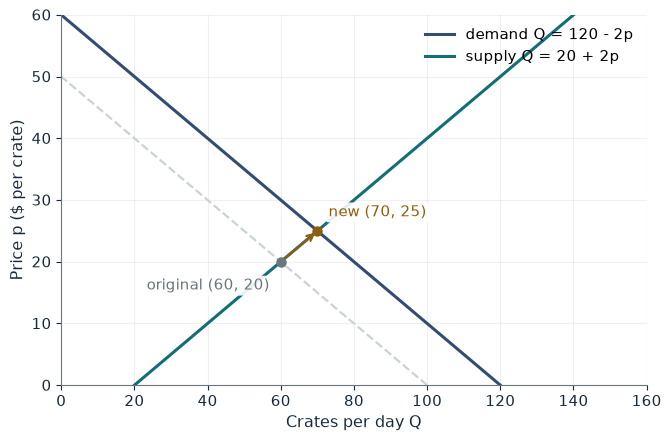

Equilibrium price p*               25
Equilibrium quantity Q*            70
Price change from 20               +5
Quantity change from 60            +10
Excess demand at the old price 20  20

Worked steps:
  1. 120 - 2p = 20 + 2p
  2. 4p = 120 - 20 = 100
  3. p* = 100 / 4 = 25
  4. Q* = 120 - 2 x 25 = 70
  5. Excess demand at 20: 80 - 60 = 20

Clearing needs 120 - 2p = 20 + 2p, so 4p = 100 and p* = 25; then Q* = 120 - 2 x 25 = 70. Compared with (60, 20), quantity changes by +10 and price rises. At the old price of 20, excess demand is (120 - 40) - (20 + 40) = 20.


In [2]:
show(clearing_picture(dshift=20, sshift=0))

Change one input, `sshift`, and hold the others at the book's values:

In [3]:
sweep(clearing_picture, 'sshift', [0, 20, 40], {'dshift': 0}, ['Equilibrium price p*', 'Equilibrium quantity Q*', 'Price change from 20'])

sshift | Equilibrium price p* | Equilibrium quantity Q* | Price change from 20
0 | 20 | 60 | 0
20 | 15 | 70 | -5
40 | 10 | 80 | -10


A demand shift of 20 raises price to 25 and quantity to 70; a supply shift of 20 also gives 70 crates but lowers price to 15. The price tells you which schedule moved.

## 2. Price controls: shortage under a ceiling

Demand $Q_D=120-2P$, supply $Q_S=20+2P$ (thousand units). At a ceiling of 15 demand is 90 and supply 50:

$$S=90-50=40$$

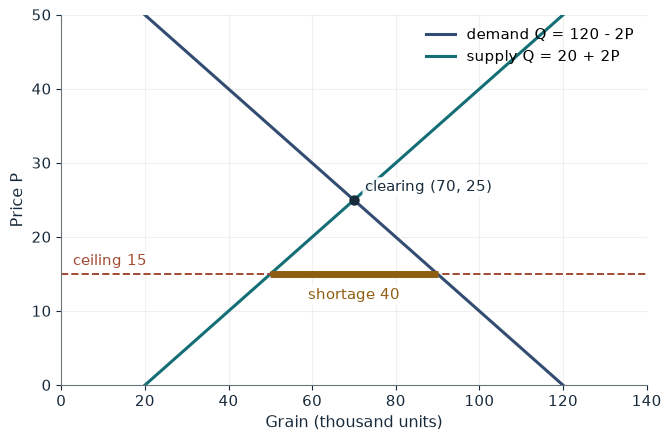

Clearing price P*  25
Legal price        15
Quantity demanded  90
Quantity supplied  50
Shortage           40
Ceiling binds      yes

Worked steps:
  1. P* = (120 - 20) / 4 = 25
  2. Legal price = 15 (ceiling binds)
  3. Demand = 120 - 2 x 15 = 90
  4. Supply = 20 + 2 x 15 = 50
  5. Shortage = 40
  6. Illicit net = 27 - 8 = 19

Clearing solves 120 - 2P = 20 + 2P, so P* = 25. At the ceiling of 15, demand is 120 - 2 x 15 = 90 and supply is 20 + 2 x 15 = 50, so the shortage is 90 - 50 = 40 thousand units. An illicit seller paid 27 with penalty costs of 8 nets 27 - 8 = 19, above the legal price of 15.


In [4]:
show(ceiling_picture(ceil=15, imp=0))

Change one input, `ceil`, and hold the others at the book's values:

In [5]:
sweep(ceiling_picture, 'ceil', [0, 20, 15, 10], {'imp': 0}, ['Legal price', 'Quantity demanded', 'Quantity supplied', 'Shortage'])

ceil | Legal price | Quantity demanded | Quantity supplied | Shortage
0 | 25 | 70 | 70 | 0
20 | 20 | 80 | 60 | 20
15 | 15 | 90 | 50 | 40
10 | 10 | 100 | 40 | 60


A ceiling of 15 leaves a shortage of 40 thousand units; imports of 20 at every price cut it to 20. An illicit seller nets 27 - 8 = 19, more than the legal 15. (Ceiling 0 in the sweep means no ceiling.)

## 3. Walrasian tatonnement: speed decides convergence

$z_1(p)=10-2p$ and $p^{t+1}=p^t+\alpha z_1(p^t)$. With $\alpha=0.25$ from $p^0=2$:

$$p^{t+1}-5=0.5(p^t-5)$$

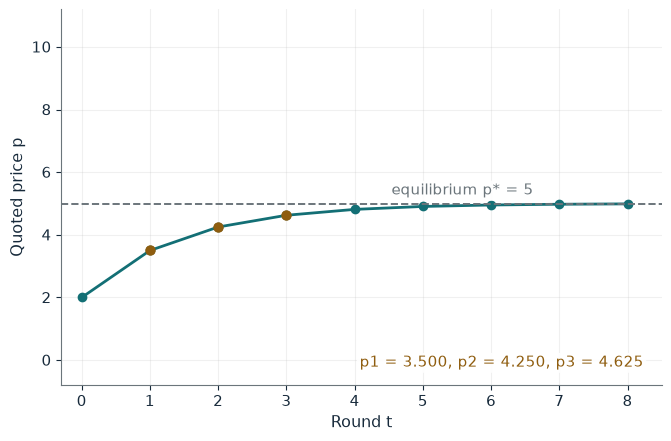

p1                  3.500
p2                  4.250
p3                  4.625
Factor 1 - 2 alpha  0.5
Gap after 8 rounds  -0.012

Worked steps:
  1. p1 = 2.000 + 0.25 x (6.000) = 3.500
  2. p2 = 3.500 + 0.25 x (3.000) = 4.250
  3. p3 = 4.250 + 0.25 x (1.500) = 4.625
  4. Factor = 1 - 2 x 0.25 = 0.5

From p0 = 2, excess demand is 10 - 2 x 2 = 6, so p1 = 2 + 0.25 x 6 = 3.500. Because z is linear, p(t+1) - 5 = (1 - 2 x 0.25)(p(t) - 5) = 0.5(p(t) - 5). The factor 0.5 has size below 1, so the gap to 5 shrinks every round.


In [6]:
show(tatonnement_picture(alpha=0.25, p0=2))

Change one input, `alpha`, and hold the others at the book's values:

In [7]:
sweep(tatonnement_picture, 'alpha', [0.25, 0.5, 1, 1.1], {'p0': 2}, ['p1', 'p2', 'p3', 'Factor 1 - 2 alpha'])

alpha | p1 | p2 | p3 | Factor 1 - 2 alpha
0.25 | 3.500 | 4.250 | 4.625 | 0.5
0.5 | 5.000 | 5.000 | 5.000 | 0.0
1 | 8.000 | 2.000 | 8.000 | -1.0
1.1 | 8.600 | 0.680 | 10.184 | -1.2


At 0.25 the path is 3.5, 4.25, 4.625, halving the gap each round. At 1 it cycles between 2 and 8; at 1.1 the gap grows 20 percent a round.

## 4. Sonnenschein-Mantel-Debreu: three equilibria

$$z_1(p)=-(p-1)(p-2)(p-3), \qquad z_1(1.5)=-(0.5)(-0.5)(-1.5)=-0.375$$

Price follows $\dot p=z_1(p)$.

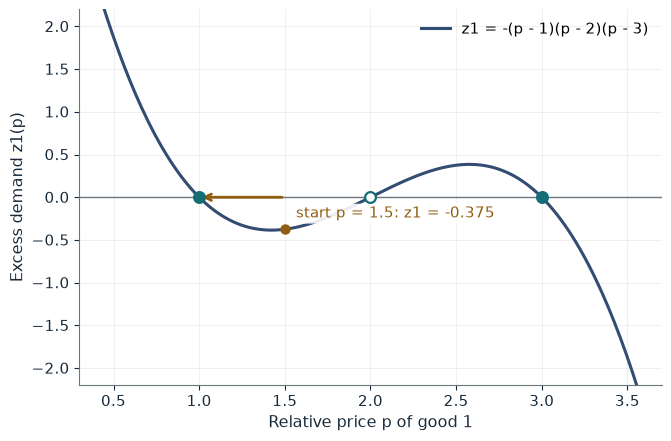

z1 at the start       -0.375
Direction of price    falls
Price settles at      1.00
Number of equilibria  3

Worked steps:
  1. z1(1.5) = -(0.5) x (-0.5) x (-1.5) = -0.375
  2. Sign negative, so price falls
  3. Nearest stable equilibrium in that direction: 1.00

At p = 1.5, z1 = -(0.5) x (-0.5) x (-1.5) = -0.375, so under dp/dt = z1 the price falls and settles at 1.00. Markets clear at p = 1, 2 and 3; 1 and 3 are stable and 2 is unstable (open dot).


In [8]:
show(smd_picture(p0=1.5, shape='cubic'))

Change one input, `p0`, and hold the others at the book's values:

In [9]:
sweep(smd_picture, 'p0', [0.5, 1.5, 2.5, 3.5], {'shape': 'cubic'}, ['z1 at the start', 'Direction of price', 'Price settles at'])

p0 | z1 at the start | Direction of price | Price settles at
0.5 | 1.875 | rises | 1.00
1.5 | -0.375 | falls | 1.00
2.5 | 0.375 | rises | 3.00
3.5 | -1.875 | falls | 3.00


Starts below 2 settle at 1 and starts above 2 settle at 3; the equilibrium at 2 is unstable. With $z_1=2-p$ every start goes to 2.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

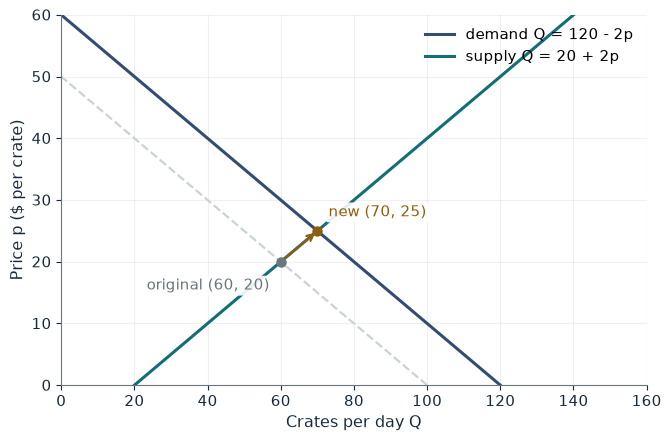

Equilibrium price p*               25
Equilibrium quantity Q*            70
Price change from 20               +5
Quantity change from 60            +10
Excess demand at the old price 20  20

Worked steps:
  1. 120 - 2p = 20 + 2p
  2. 4p = 120 - 20 = 100
  3. p* = 100 / 4 = 25
  4. Q* = 120 - 2 x 25 = 70
  5. Excess demand at 20: 80 - 60 = 20

Clearing needs 120 - 2p = 20 + 2p, so 4p = 100 and p* = 25; then Q* = 120 - 2 x 25 = 70. Compared with (60, 20), quantity changes by +10 and price rises. At the old price of 20, excess demand is (120 - 40) - (20 + 40) = 20.


In [10]:
show(clearing_picture(dshift=20, sshift=0))

## Practice

**1.** With a demand shift of +40 and a supply shift of +20, what are price and quantity?

<details><summary>Answer</summary>

140 - 2p = 40 + 2p gives p = 25 and Q = 90.

</details>

**2.** With a ceiling of 10 and imports of 20, what is the shortage?

<details><summary>Answer</summary>

Demand 120 - 20 = 100, supply 20 + 20 + 20 = 60, shortage 40 thousand units.

</details>

**3.** What is z1(3.5) under the cubic, and which way does price move?

<details><summary>Answer</summary>

-(2.5)(1.5)(0.5) = -1.875, negative, so price falls toward 3.

</details>